# Assignment 03 — Toxic Comment Classification with BERT
**Transfer learning · Fine-tuning · Hyperparameter tuning · Interpretability (LIME)**

**Name: Nazifa Alam**

**Student ID: 1000128863**


## 1. Setup

In [ ]:
!pip -q install datasets transformers lime scikit-learn

In [ ]:
import os, gc, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import set_seed

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

print("PyTorch:", torch.__version__)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU - training will be very slow")
os.makedirs("figures", exist_ok=True)

PyTorch: 2.11.0+cu130
Device: cuda | Tesla T4


In [ ]:
#Configuration
MODEL_NAME         = "bert-base-uncased"
TOXICITY_THRESHOLD = 0.5      #toxicity >= 0.5 -> toxic (1)
MAX_LENGTH         = 200
BATCH_SIZE         = 16
TRAIN_PER_CLASS    = 4000     # balanced training subset: 4000 toxic + 4000 non-toxic
EVAL_PER_CLASS     = 1000     # balanced validation / test: 1000 toxic + 1000 non-toxic each
EVAL_SIZE          = 2 * EVAL_PER_CLASS   # (used by the save cell)
BEST_PATH          = "best_model.pt"

## 2. Data: Civil Comments

In [ ]:
from datasets import load_dataset

dataset = load_dataset("google/civil_comments")
for split in dataset.keys():
    print(f"{split}: {len(dataset[split]):,} comments")
print("Columns:", dataset["train"].column_names)
print("\nFirst comment:", dataset["train"][0]["text"])
print("Toxicity score:", dataset["train"][0]["toxicity"])

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

train: 1,804,874 comments
validation: 97,320 comments
test: 97,320 comments
Columns: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

First comment: This is so cool. It's like, 'would you want your mother to read this??' Really great idea, well done!
Toxicity score: 0.0


**Binary labels** — a comment is toxic (1) if `toxicity >= 0.5`, otherwise non-toxic (0).

In [ ]:
def add_binary_label(batch):
    return {"label": [int(t >= TOXICITY_THRESHOLD) for t in batch["toxicity"]]}

dataset = dataset.map(add_binary_label, batched=True)

train_labels_full = np.array(dataset["train"]["label"])
counts = np.bincount(train_labels_full, minlength=2)
print("Full training set  ->  Non-toxic:", counts[0], "| Toxic:", counts[1])
print(f"Toxic share: {counts[1] / counts.sum() * 100:.2f}%")

Map:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Map:   0%|          | 0/97320 [00:00<?, ? examples/s]

Map:   0%|          | 0/97320 [00:00<?, ? examples/s]

Full training set  ->  Non-toxic: 1660540 | Toxic: 144334
Toxic share: 8.00%


**Sampling:** 8,000 balanced training examples and 2,000 balanced examples each for validation and testing. Balanced sampling reduces class imbalance but does not represent the original dataset's toxic-comment prevalence.

In [ ]:
from datasets import DatasetDict

rng = np.random.default_rng(SEED)

def balanced_indices(labels, per_class, rng):
    idx = np.concatenate([
        rng.choice(np.where(labels == 0)[0], size=per_class, replace=False),
        rng.choice(np.where(labels == 1)[0], size=per_class, replace=False),
    ])
    return idx

val_labels_full  = np.array(dataset["validation"]["label"])
test_labels_full = np.array(dataset["test"]["label"])

train_indices = balanced_indices(train_labels_full, TRAIN_PER_CLASS, rng)

small_dataset = DatasetDict({
    "train":      dataset["train"].select(train_indices),
    "validation": dataset["validation"].select(balanced_indices(val_labels_full,  EVAL_PER_CLASS, rng)),
    "test":       dataset["test"].select(balanced_indices(test_labels_full, EVAL_PER_CLASS, rng)),
})

for split in small_dataset:
    y = np.array(small_dataset[split]["label"])
    print(f"{split:<10} total={len(y):>5} | non-toxic={np.sum(y == 0):>5} | toxic={np.sum(y == 1):>5} ({np.mean(y) * 100:.1f}% toxic)")

train      total= 8000 | non-toxic= 4000 | toxic= 4000 (50.0% toxic)
validation total= 2000 | non-toxic= 1000 | toxic= 1000 (50.0% toxic)
test       total= 2000 | non-toxic= 1000 | toxic= 1000 (50.0% toxic)


## 3. Tokenization and DataLoaders:
BERT tokenization with a maximum sequence length of 200 and dynamic batch padding.

In [ ]:
from transformers import AutoTokenizer, DataCollatorWithPadding
from torch.utils.data import DataLoader

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sample = tokenizer("You are helpful!")
print("Tokens:", tokenizer.convert_ids_to_tokens(sample["input_ids"]))
print("Input IDs:", sample["input_ids"])

def tokenize_comments(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = small_dataset.map(tokenize_comments, batched=True)

keep = {"input_ids", "attention_mask", "token_type_ids", "label"}
def prepare(split):
    data = tokenized_dataset[split]
    return data.remove_columns([c for c in data.column_names if c not in keep])

collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

train_loader = DataLoader(prepare("train"),      batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collator)
val_loader   = DataLoader(prepare("validation"), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)
test_loader  = DataLoader(prepare("test"),       batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)

batch = next(iter(train_loader))
print("\nBatches (train/val/test):", len(train_loader), len(val_loader), len(test_loader))
print("Batch keys:", list(batch.keys()), "| input shape:", tuple(batch["input_ids"].shape))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokens: ['[CLS]', 'you', 'are', 'helpful', '!', '[SEP]']
Input IDs: [101, 2017, 2024, 14044, 999, 102]


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]


Batches (train/val/test): 500 125 125
Batch keys: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'] | input shape: (16, 200)


## 4. Training and evaluation helpers
All experiments use the same training procedure. The checkpoint with the highest validation PR-AUC is retained.

In [ ]:
from torch.optim import AdamW
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss,
                             classification_report, confusion_matrix)

def collect_probabilities(model, loader):
    """Return (labels, P(toxic)) for every example in the loader."""
    model.eval()
    labels, probs = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            y = batch.pop("labels")
            logits = model(**batch).logits
            probs.extend(torch.softmax(logits.float(), dim=1)[:, 1].cpu().tolist())
            labels.extend(y.cpu().tolist())
    return np.array(labels), np.array(probs)

def compute_metrics(labels, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    recall, specificity = tp / (tp + fn), tn / (tn + fp)
    return {
        "accuracy":     accuracy_score(labels, preds),
        "precision":    precision_score(labels, preds, zero_division=0),
        "recall":       recall,
        "specificity":  specificity,
        "balanced_acc": (recall + specificity) / 2,
        "f1":           f1_score(labels, preds, zero_division=0),
        "roc_auc":      roc_auc_score(labels, probs),
        "pr_auc":       average_precision_score(labels, probs),
    }

def print_report(labels, probs, threshold, title):
    preds = (probs >= threshold).astype(int)
    print(f"{title}  (threshold = {threshold})")
    print(classification_report(labels, preds, target_names=["Non-toxic", "Toxic"], digits=4, zero_division=0))
    print("Confusion matrix [[TN FP], [FN TP]]:")
    print(confusion_matrix(labels, preds, labels=[0, 1]))

In [ ]:
runs = {}                       # name -> results of each experiment
best_name, best_score = None, -1.0   # best full fine-tuning run by validation PR-AUC

def run_experiment(name, stage, lr, weight_decay=0.0, epochs=3, freeze_encoder=False):
    set_seed(SEED)                                   # identical start for every run
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

    if freeze_encoder:                               # transfer learning: encoder is a fixed feature extractor
        for p in model.bert.parameters():
            p.requires_grad = False
        assert all(not p.requires_grad for p in model.bert.parameters())
        assert all(p.requires_grad for p in model.classifier.parameters())

    params = [p for p in model.parameters() if p.requires_grad]
    n_train = sum(p.numel() for p in params)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"\n>>> {name} | lr={lr} wd={weight_decay} epochs={epochs} | trainable {n_train:,}/{n_total:,}")

    optimizer = AdamW(params, lr=lr, weight_decay=weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history, best_ap, best_epoch, best_state = [], -1.0, 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        if freeze_encoder:
            model.bert.eval()                        # no dropout inside the frozen encoder
        total_loss = 0.0
        for batch in tqdm(train_loader, desc=f"{name} | epoch {epoch}/{epochs}", leave=False):
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item()

        v_labels, v_probs = collect_probabilities(model, val_loader)
        v_loss = log_loss(v_labels, np.clip(v_probs, 1e-7, 1 - 1e-7))
        v_ap = average_precision_score(v_labels, v_probs)
        history.append({"epoch": epoch, "train_loss": total_loss / len(train_loader),
                        "val_loss": v_loss, "val_pr_auc": v_ap})
        print(f"epoch {epoch}: train_loss={history[-1]['train_loss']:.4f} "
              f"val_loss={v_loss:.4f} val_PR-AUC={v_ap:.4f}")

        if v_ap > best_ap:
            best_ap, best_epoch = v_ap, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)                # restore best epoch
    v_labels, v_probs = collect_probabilities(model, val_loader)
    t_labels, t_probs = collect_probabilities(model, test_loader)   # stored only for the final table; never used for selection

    runs[name] = {"stage": stage, "lr": lr, "weight_decay": weight_decay, "epochs": epochs,
                  "best_epoch": best_epoch, "history": history, "val_pr_auc": best_ap,
                  "val_labels": v_labels, "val_probs": v_probs,
                  "test_labels": t_labels, "test_probs": t_probs}

    global best_name, best_score
    if stage != "frozen" and best_ap > best_score:   # keep only the single best full fine-tuned checkpoint
        best_name, best_score = name, best_ap
        torch.save(best_state, BEST_PATH)

    del model, optimizer, best_state
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

## 5. Experiment 1 — Frozen BERT (transfer learning baseline)
The BERT encoder is frozen; only the classification head is trained.

In [ ]:
run_experiment("Frozen BERT", stage="frozen", lr=1e-3, epochs=3, freeze_encoder=True)

r = runs["Frozen BERT"]
print_report(r["val_labels"], r["val_probs"], 0.5, "FROZEN BERT - VALIDATION")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



>>> Frozen BERT | lr=0.001 wd=0.0 epochs=3 | trainable 1,538/109,483,778


Frozen BERT | epoch 1/3:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 1: train_loss=0.6651 val_loss=0.6532 val_PR-AUC=0.7735


Frozen BERT | epoch 2/3:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 2: train_loss=0.6126 val_loss=0.5669 val_PR-AUC=0.7881


Frozen BERT | epoch 3/3:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 3: train_loss=0.5881 val_loss=0.5825 val_PR-AUC=0.7895
FROZEN BERT - VALIDATION  (threshold = 0.5)
              precision    recall  f1-score   support

   Non-toxic     0.6289    0.8830    0.7346      1000
       Toxic     0.8037    0.4790    0.6003      1000

    accuracy                         0.6810      2000
   macro avg     0.7163    0.6810    0.6674      2000
weighted avg     0.7163    0.6810    0.6674      2000

Confusion matrix [[TN FP], [FN TP]]:
[[883 117]
 [521 479]]


## 6. Experiment 2 — Full fine-tuning (default settings, no tuning)
All parameters are unfrozen and trained end-to-end with the common BERT defaults: learning rate 2e-5, weight decay 0, 2 epochs.

In [ ]:
run_experiment("Fine-tuned (default)", stage="default", lr=2e-5, weight_decay=0.0, epochs=2)

r = runs["Fine-tuned (default)"]
print_report(r["val_labels"], r["val_probs"], 0.5, "FULL FINE-TUNING (DEFAULT) - VALIDATION")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



>>> Fine-tuned (default) | lr=2e-05 wd=0.0 epochs=2 | trainable 109,483,778/109,483,778


Fine-tuned (default) | epoch 1/2:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 1: train_loss=0.4024 val_loss=0.3027 val_PR-AUC=0.9434


Fine-tuned (default) | epoch 2/2:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 2: train_loss=0.2310 val_loss=0.4202 val_PR-AUC=0.9396
FULL FINE-TUNING (DEFAULT) - VALIDATION  (threshold = 0.5)
              precision    recall  f1-score   support

   Non-toxic     0.9130    0.8190    0.8635      1000
       Toxic     0.8359    0.9220    0.8768      1000

    accuracy                         0.8705      2000
   macro avg     0.8745    0.8705    0.8702      2000
weighted avg     0.8745    0.8705    0.8702      2000

Confusion matrix [[TN FP], [FN TP]]:
[[819 181]
 [ 78 922]]


## 7. Hyperparameter tuning
Method: Grid search with 3 learning rates × 2 weight decay values (6 trials). The best configuration is identified using validation PR-AUC.

In [ ]:
LR_GRID = [5e-6, 1e-5, 3e-5]
WD_GRID = [0.0, 0.01]

for lr in LR_GRID:
    for wd in WD_GRID:
        run_experiment(f"Tuned lr={lr:g} wd={wd:g}", stage="tuning", lr=lr, weight_decay=wd, epochs=2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



>>> Tuned lr=5e-06 wd=0 | lr=5e-06 wd=0.0 epochs=2 | trainable 109,483,778/109,483,778


Tuned lr=5e-06 wd=0 | epoch 1/2:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 1: train_loss=0.4963 val_loss=0.3906 val_PR-AUC=0.9251


Tuned lr=5e-06 wd=0 | epoch 2/2:   0%|          | 0/500 [00:00<?, ?it/s]

... (32 outputs left out)

Tuned lr=3e-05 wd=0.01 | epoch 1/2:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 1: train_loss=0.3889 val_loss=0.3304 val_PR-AUC=0.9403


Tuned lr=3e-05 wd=0.01 | epoch 2/2:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 2: train_loss=0.2165 val_loss=0.4358 val_PR-AUC=0.9339


## 8. Comparison and model selection (validation set, default threshold 0.5)
Models are compared using validation metrics at the default threshold of 0.5.

In [ ]:
stage_order = {"frozen": 0, "default": 1, "tuning": 2}
rows = []
for name, r in runs.items():
    m = compute_metrics(r["val_labels"], r["val_probs"], 0.5)
    rows.append({"Run": name, "Stage": r["stage"], "LR": r["lr"], "Weight decay": r["weight_decay"],
                 "Epochs": r["epochs"], "Best epoch": r["best_epoch"], **m})

val_table = pd.DataFrame(rows)
val_table["_o"] = val_table["Stage"].map(stage_order)
val_table = val_table.sort_values(["_o", "pr_auc"], ascending=[True, False]).drop(columns="_o").reset_index(drop=True)
val_table = val_table.rename(columns={"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
                                      "specificity": "Specificity", "balanced_acc": "Balanced acc",
                                      "f1": "F1", "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"})
val_table["Selected"] = np.where(val_table["Run"] == best_name, "<-- best", "")
display(val_table.round(4))

print("\nSelected model:", best_name, "| validation PR-AUC =", round(best_score, 4))

,Run,Stage,LR,Weight decay,Epochs,Best epoch,Accuracy,Precision,Recall,Specificity,Balanced acc,F1,ROC-AUC,PR-AUC,Selected
0,Frozen BERT,frozen,0.001,0.00,3,3,0.6810,0.8037,0.479,0.883,0.6810,0.6003,0.8004,0.7895,
1,Fine-tuned (default),default,0.000,0.00,2,1,0.8705,0.8359,0.922,0.819,0.8705,0.8768,0.9474,0.9434,<-- best
2,Tuned lr=1e-05 wd=0.01,tuning,0.000,0.01,2,2,0.8720,0.8742,0.869,0.875,0.8720,0.8716,0.9439,0.9423,
3,Tuned lr=1e-05 wd=0,tuning,0.000,0.00,2,2,0.8730,0.8723,0.874,0.872,0.8730,0.8731,0.9446,0.9421,
4,Tuned lr=3e-05 wd=0,tuning,0.000,0.00,2,1,0.8745,0.8420,0.922,0.827,0.8745,0.8802,0.9465,0.9414,
5,Tuned lr=3e-05 wd=0.01,tuning,0.000,0.01,2,1,0.8690,0.8203,0.945,0.793,0.8690,0.8783,0.9448,0.9403,
6,Tuned lr=5e-06 wd=0.01,tuning,0.000,0.01,2,2,0.8660,0.8427,0.900,0.832,0.8660,0.8704,0.9413,0.9395,
7,Tuned lr=5e-06 wd=0,tuning,0.000,0.00,2,2,0.8690,0.8417,0.909,0.829,0.8690,0.8740,0.9422,0.9394,



Selected model: Fine-tuned (default) | validation PR-AUC = 0.9434


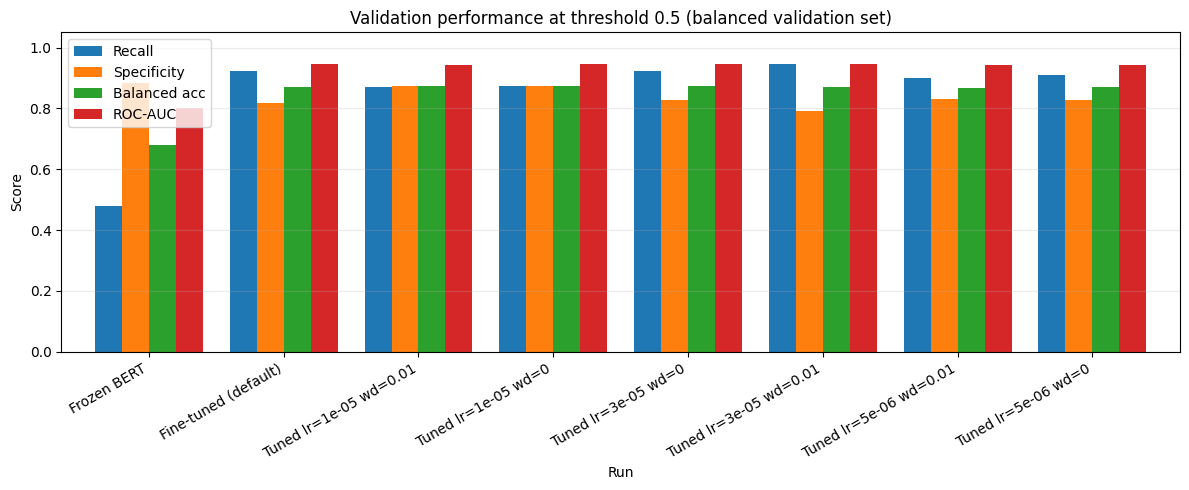

In [ ]:
plot_df = val_table.set_index("Run")[["Recall", "Specificity", "Balanced acc", "ROC-AUC"]]
ax = plot_df.plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Validation performance at threshold 0.5 (balanced validation set)")
ax.set_ylabel("Score"); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig("figures/validation_comparison.png", dpi=150)
plt.show()

## 9. Decision-threshold tuning (validation set only)
The classification threshold is selected on the validation set by maximizing balanced accuracy.

Best validation threshold (max balanced accuracy): 0.55


,Threshold,recall,specificity,balanced_acc,precision,f1
5,0.10,0.992,0.613,0.8025,0.7194,0.8340
15,0.20,0.978,0.720,0.8490,0.7774,0.8663
25,0.30,0.960,0.757,0.8585,0.7980,0.8715
35,0.40,0.943,0.792,0.8675,0.8193,0.8768
45,0.50,0.922,0.819,0.8705,0.8359,0.8768
50,0.55,0.913,0.836,0.8745,0.8477,0.8792
55,0.60,0.893,0.850,0.8715,0.8562,0.8742
65,0.70,0.865,0.876,0.8705,0.8746,0.8698
75,0.80,0.807,0.909,0.8580,0.8987,0.8504
85,0.90,0.681,0.951,0.8160,0.9329,0.7873


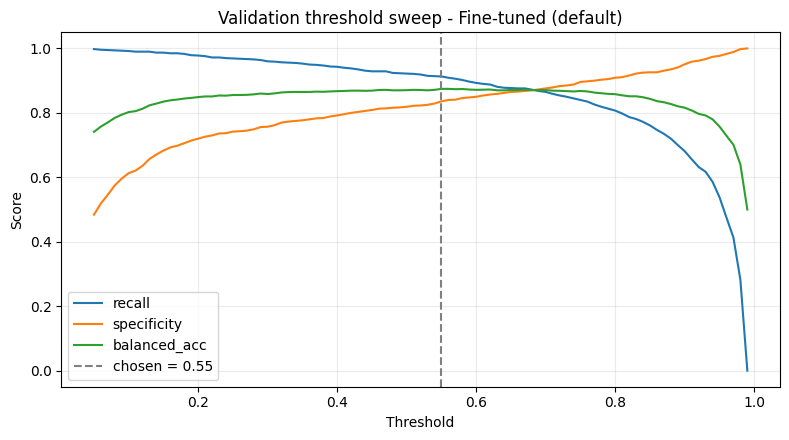

In [ ]:
sel = runs[best_name]
thr_rows = []
for t in np.arange(0.05, 1.00, 0.01):
    m = compute_metrics(sel["val_labels"], sel["val_probs"], t)
    thr_rows.append({"Threshold": round(float(t), 2),
                     **{k: m[k] for k in ["recall", "specificity", "balanced_acc", "precision", "f1"]}})
threshold_table = pd.DataFrame(thr_rows)

# choose the threshold with the highest balanced accuracy on VALIDATION (ties -> closest to 0.5)
threshold_table["_d"] = (threshold_table["Threshold"] - 0.5).abs()
best_row = threshold_table.sort_values(["balanced_acc", "_d"], ascending=[False, True]).iloc[0]
best_threshold = float(best_row["Threshold"])
threshold_table = threshold_table.drop(columns="_d")
print("Best validation threshold (max balanced accuracy):", best_threshold)

display(threshold_table[threshold_table["Threshold"].round(2).isin(np.round(np.arange(0.1, 1.0, 0.1), 2).tolist() + [best_threshold])].round(4))

plt.figure(figsize=(8, 4.5))
for col in ["recall", "specificity", "balanced_acc"]:
    plt.plot(threshold_table["Threshold"], threshold_table[col], label=col)
plt.axvline(best_threshold, color="gray", linestyle="--", label=f"chosen = {best_threshold}")
plt.xlabel("Threshold"); plt.ylabel("Score"); plt.title(f"Validation threshold sweep - {best_name}")
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout()
plt.savefig("figures/threshold_sweep.png", dpi=150)
plt.show()

## 10. Final evaluation on the test set
The validation-selected model is evaluated on the test set using the default and optimized thresholds.

In [ ]:
final_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
final_model.load_state_dict(torch.load(BEST_PATH, map_location="cpu", weights_only=True))
final_model.to(device).eval()

test_labels, test_probs = collect_probabilities(final_model, test_loader)

print_report(test_labels, test_probs, 0.5,            f"{best_name} - TEST")
print("\n" + "=" * 60 + "\n")
print_report(test_labels, test_probs, best_threshold, f"{best_name} - TEST")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fine-tuned (default) - TEST  (threshold = 0.5)
              precision    recall  f1-score   support

   Non-toxic     0.9328    0.8050    0.8642      1000
       Toxic     0.8285    0.9420    0.8816      1000

    accuracy                         0.8735      2000
   macro avg     0.8806    0.8735    0.8729      2000
weighted avg     0.8806    0.8735    0.8729      2000

Confusion matrix [[TN FP], [FN TP]]:
[[805 195]
 [ 58 942]]


Fine-tuned (default) - TEST  (threshold = 0.55)
              precision    recall  f1-score   support

   Non-toxic     0.9226    0.8220    0.8694      1000
       Toxic     0.8395    0.9310    0.8829      1000

    accuracy                         0.8765      2000
   macro avg     0.8810    0.8765    0.8761      2000
weighted avg     0.8810    0.8765    0.8761      2000

Confusion matrix [[TN FP], [FN TP]]:
[[822 178]
 [ 69 931]]


,Model,Threshold,Accuracy,Precision,Recall,Specificity,Balanced acc,F1,ROC-AUC,PR-AUC
0,Frozen BERT,0.50,0.6810,0.8007,0.482,0.880,0.6810,0.6017,0.7907,0.7797
1,Fine-tuned (default),0.50,0.8735,0.8285,0.942,0.805,0.8735,0.8816,0.9457,0.9399
2,Best tuned: Fine-tuned (default),0.50,0.8735,0.8285,0.942,0.805,0.8735,0.8816,0.9457,0.9399
3,Best tuned: Fine-tuned (default) + tuned thr,0.55,0.8765,0.8395,0.931,0.822,0.8765,0.8829,0.9457,0.9399


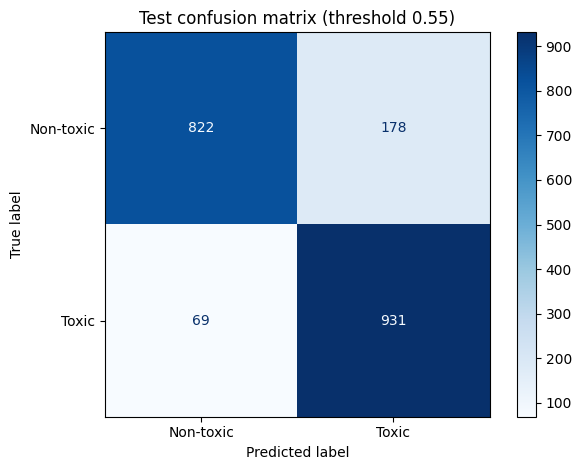

In [ ]:
test_rows = [
    {"Model": "Frozen BERT",                         "Threshold": 0.5,
     **compute_metrics(runs["Frozen BERT"]["test_labels"], runs["Frozen BERT"]["test_probs"], 0.5)},
    {"Model": "Fine-tuned (default)",                "Threshold": 0.5,
     **compute_metrics(runs["Fine-tuned (default)"]["test_labels"], runs["Fine-tuned (default)"]["test_probs"], 0.5)},
    {"Model": f"Selected model: {best_name}",            "Threshold": 0.5,
     **compute_metrics(test_labels, test_probs, 0.5)},
    {"Model": f"Selected model: {best_name} + tuned thr", "Threshold": best_threshold,
     **compute_metrics(test_labels, test_probs, best_threshold)},
]
test_table = pd.DataFrame(test_rows).rename(columns={"accuracy": "Accuracy", "precision": "Precision",
        "recall": "Recall", "specificity": "Specificity", "balanced_acc": "Balanced acc",
        "f1": "F1", "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"})
display(test_table.round(4))

from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(test_labels, (test_probs >= best_threshold).astype(int), labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Non-toxic", "Toxic"]).plot(cmap="Blues", values_format="d")
plt.title(f"Test confusion matrix (threshold {best_threshold})")
plt.tight_layout(); plt.savefig("figures/test_confusion_matrix.png", dpi=150); plt.show()

## 11. Real-world text test
Eight new comments are tested and compared against manually assigned expected labels.

In [ ]:
def predict_proba(texts, bs=64):
    """Batched class probabilities [P(non-toxic), P(toxic)] for the selected model (used by LIME too)."""
    final_model.eval()
    out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(list(texts[i:i + bs]), padding=True, truncation=True,
                        max_length=MAX_LENGTH, return_tensors="pt").to(device)
        with torch.no_grad():
            out.append(torch.softmax(final_model(**enc).logits.float(), dim=1).cpu().numpy())
    return np.concatenate(out)

real_world = [
    ("Thanks for sharing this, the explanation was really helpful.",                          "Non-toxic"),
    ("You are a complete idiot and nobody wants to hear your opinions.",                      "Toxic"),
    ("I disagree with the mayor's budget, but I appreciate that the council debated it openly.", "Non-toxic"),
    ("People like you should just shut up and disappear.",                                    "Toxic"),
    ("The movie was so bad I wanted to walk out, the acting was garbage.",                    "Non-toxic"),
    ("He called me an idiot yesterday and it really hurt.",                                   "Non-toxic"),
    ("Great, another genius decision from management. Truly brilliant.",                      "Non-toxic"),
    ("Go back to where you came from.",                                                       "Toxic"),
]
texts = [t for t, _ in real_world]
rw_probs = predict_proba(texts)[:, 1]

rw_df = pd.DataFrame({
    "Input": texts,
    "P(toxic)": rw_probs.round(4),
    "Predicted": np.where(rw_probs >= best_threshold, "Toxic", "Non-toxic"),
    "Expected": [e for _, e in real_world],
})
rw_df["Match"] = np.where(rw_df["Predicted"] == rw_df["Expected"], "yes", "NO")
pd.set_option("display.max_colwidth", 100)
display(rw_df)

,Input,P(toxic),Predicted,Expected,Match
0,"Thanks for sharing this, the explanation was really helpful.",0.0109,Non-toxic,Non-toxic,yes
1,You are a complete idiot and nobody wants to hear your opinions.,0.9843,Toxic,Toxic,yes
2,"I disagree with the mayor's budget, but I appreciate that the council debated it openly.",0.0125,Non-toxic,Non-toxic,yes
3,People like you should just shut up and disappear.,0.9618,Toxic,Toxic,yes
4,"The movie was so bad I wanted to walk out, the acting was garbage.",0.9806,Toxic,Non-toxic,NO
5,He called me an idiot yesterday and it really hurt.,0.9843,Toxic,Non-toxic,NO
6,"Great, another genius decision from management. Truly brilliant.",0.0163,Non-toxic,Non-toxic,yes
7,Go back to where you came from.,0.0364,Non-toxic,Toxic,NO


## 12. Interpretability with LIME
LIME estimates how individual words influence predictions. True positives, false positives, false negatives and true negatives are examined.


=== True positive | actual=1 predicted=1 | P(toxic)=0.987
You AND RLH? Bonus stupidity.
Word contributions toward Toxic: [('stupidity', 0.9417), ('AND', -0.016), ('Bonus', -0.0156), ('RLH', 0.0035), ('You', 0.0005)]


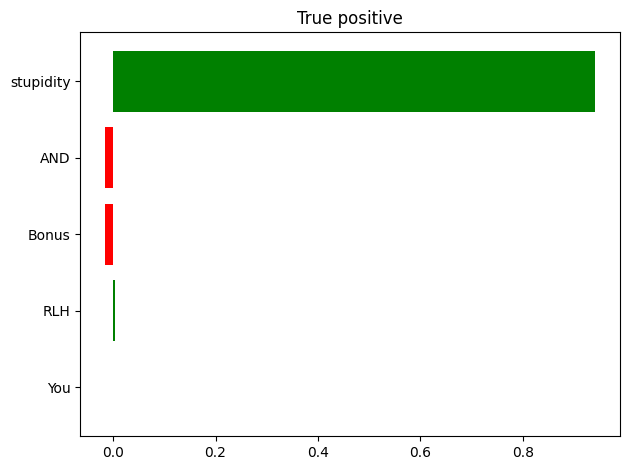


=== False positive | actual=0 predicted=1 | P(toxic)=0.984
Ah, 'Tall Guy' leasing. Anchorages Premier bus leasing company.

Frankly I hope that Trooper feels like a fool cause those folks on that bus sure played him for one.
Word contributions toward Toxic: [('fool', 0.8823), ('leasing', -0.0312), ('a', 0.0307), ('Guy', 0.0253), ('Trooper', 0.0223), ('cause', 0.0174), ('those', -0.0163), ('Tall', 0.0105)]


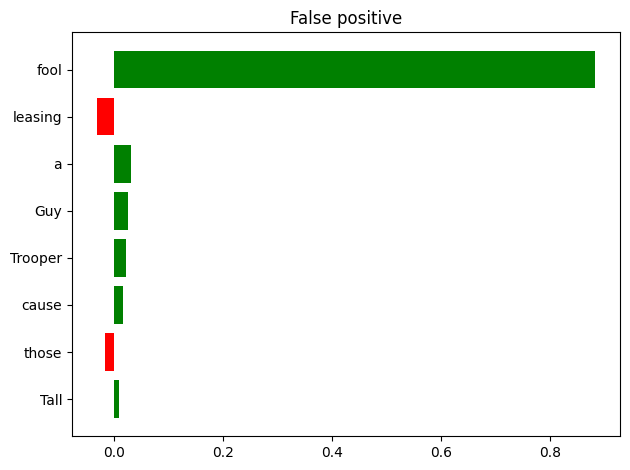


=== False negative | actual=1 predicted=0 | P(toxic)=0.031
"Presidents travel with the equivalent of a mini-White House......the work of being president continues, and they must be prepared to handle a crisis at all hours and from wherever they are."

So this guy ALWAYS holds the controls of our nuclear weapons.  Even when on the golf course and has had a bad round? Even after someone makes fun of his small hands?  How good and secure does that make you f
Word contributions toward Toxic: [('House', -0.1356), ('White', 0.0732), ('fun', 0.0282), ('travel', -0.0205), ('a', 0.0183), ('the', -0.0161), ('president', 0.0157), ('with', -0.0141)]


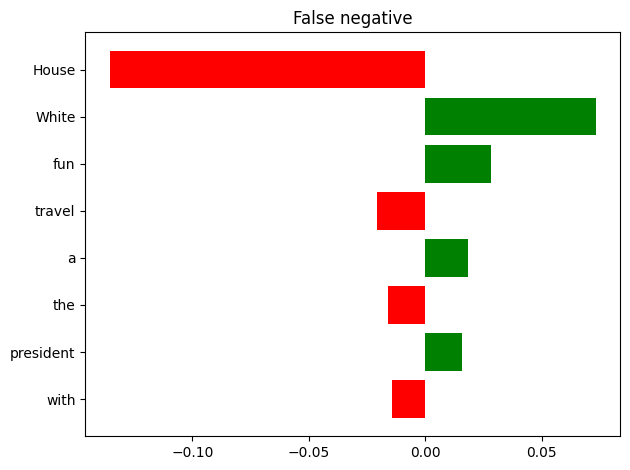


=== True negative | actual=0 predicted=0 | P(toxic)=0.010
Would that alternative include HR 5714? It would require retired postal employees to buy into Medicare to keep their health insurance.
Word contributions toward Toxic: [('insurance', -0.0046), ('Medicare', -0.0035), ('Would', -0.0031), ('employees', -0.0024), ('that', -0.0022), ('would', -0.0014), ('retired', 0.0012), ('health', 0.001)]


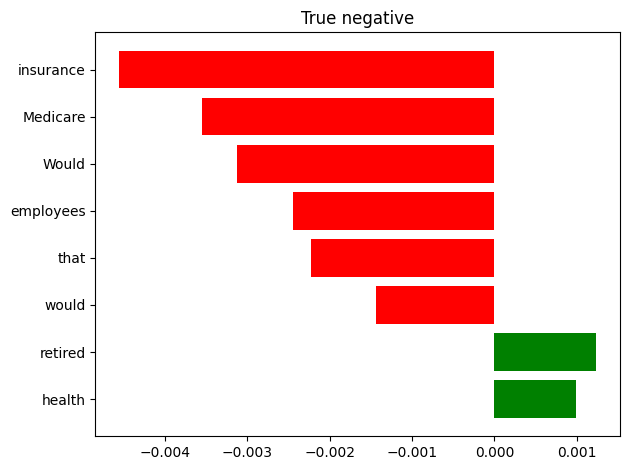

In [ ]:
from lime.lime_text import LimeTextExplainer

test_texts = small_dataset["test"]["text"]
test_preds = (test_probs >= best_threshold).astype(int)

def pick(mask, highest=True):
    idx = np.where(mask)[0]
    return int(idx[np.argmax(test_probs[idx])] if highest else idx[np.argmin(test_probs[idx])])

cases = {
    "True positive":  pick((test_preds == 1) & (test_labels == 1), highest=True),
    "False positive": pick((test_preds == 1) & (test_labels == 0), highest=True),
    "False negative": pick((test_preds == 0) & (test_labels == 1), highest=False),
    "True negative":  pick((test_preds == 0) & (test_labels == 0), highest=False),
}

explainer = LimeTextExplainer(class_names=["Non-toxic", "Toxic"], random_state=SEED)
lime_results = {}

for case, i in cases.items():
    exp = explainer.explain_instance(test_texts[i], predict_proba, num_features=8, num_samples=2000)
    contrib = [(str(w), round(float(s), 4)) for w, s in exp.as_list(label=1)]
    lime_results[case] = {"text": test_texts[i], "actual": int(test_labels[i]),
                          "predicted": int(test_preds[i]), "p_toxic": float(test_probs[i]),
                          "contributions": contrib}
    print(f"\n=== {case} | actual={test_labels[i]} predicted={test_preds[i]} | P(toxic)={test_probs[i]:.3f}")
    print(test_texts[i][:400])
    print("Word contributions toward Toxic:", contrib)

    fig = exp.as_pyplot_figure(label=1)
    plt.title(case); plt.tight_layout()
    plt.savefig(f"figures/lime_{case.lower().replace(' ', '_')}.png", dpi=150)
    plt.show()
    exp.save_to_file(f"figures/lime_{case.lower().replace(' ', '_')}.html")

In [ ]:
# Optional: LIME on the real-world texts (mention-vs-use and sarcasm are the interesting ones)
for idx in [1, 5, 6]:
    exp = explainer.explain_instance(texts[idx], predict_proba, num_features=8, num_samples=2000)
    print(f"\n{texts[idx]}\n   P(toxic)={rw_probs[idx]:.3f} ->", [(str(w), round(float(s), 3)) for w, s in exp.as_list(label=1)])


You are a complete idiot and nobody wants to hear your opinions.
   P(toxic)=0.984 -> [('idiot', 0.688), ('nobody', 0.135), ('and', -0.063), ('a', 0.061), ('complete', 0.032), ('hear', -0.027), ('You', 0.027), ('are', 0.021)]

He called me an idiot yesterday and it really hurt.
   P(toxic)=0.984 -> [('idiot', 0.769), ('hurt', 0.093), ('it', -0.051), ('yesterday', -0.033), ('He', 0.012), ('me', 0.01), ('an', 0.007), ('really', 0.006)]

Great, another genius decision from management. Truly brilliant.
   P(toxic)=0.016 -> [('decision', -0.029), ('Truly', -0.018), ('genius', 0.018), ('management', -0.01), ('another', -0.008), ('Great', -0.008), ('from', -0.003), ('brilliant', -0.002)]


## 13. Save results

In [ ]:
val_table.to_csv("results_validation.csv", index=False)
test_table.to_csv("results_test.csv", index=False)
threshold_table.to_csv("results_threshold_sweep.csv", index=False)
rw_df.to_csv("results_real_world.csv", index=False)

summary = {
    "seed": SEED, "model": MODEL_NAME, "label_threshold": TOXICITY_THRESHOLD,
    "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE,
    "train_size": 2 * TRAIN_PER_CLASS, "eval_size": EVAL_SIZE,
    "selected_run": best_name, "selected_val_pr_auc": best_score,
    "decision_threshold": best_threshold,
    "lime": lime_results,
}
with open("results_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved: results_validation.csv, results_test.csv, results_threshold_sweep.csv, results_real_world.csv, results_summary.json, figures/*")

Saved: results_validation.csv, results_test.csv, results_threshold_sweep.csv, results_real_world.csv, results_summary.json, figures/*
